# Task 1 - Smart Buildings: Dataset Understanding and Probability

**Member 1 - Data Lead**

> Member 5: replace this starter with the final problem statement, objectives, and roadmap before submission.

This notebook analyzes the Smart Buildings generator dataset. It documents the source files, defines a reproducible analysis frame, checks data quality, and publishes shared event columns for the probability applications. Later sections are reserved for the team. Results describe this generator's accepted outputs, not real-world buildings.

## 1. Setup (Member 1)

Load the three source CSVs without editing them. The notebook first checks its current folder and the usual shared Drive folder. If the files are not there and this is Colab, it asks you to upload the three CSVs. If running locally, keep this notebook beside the CSVs or set `DATA_DIR` to their folder.

In [21]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

REQUIRED_FILES = ['buildings_200_features.csv', 'rejected_seeds.csv', 'feature_catalog.csv']
candidate_dirs = [Path.cwd(), Path('/content/drive/MyDrive/stats_project')]
DATA_DIR = next((p for p in candidate_dirs if all((p / f).exists() for f in REQUIRED_FILES)), None)

if DATA_DIR is None:
    try:
        from google.colab import files
        print('Upload buildings_200_features.csv, rejected_seeds.csv, and feature_catalog.csv')
        files.upload()
        DATA_DIR = Path.cwd()
    except ImportError:
        raise FileNotFoundError(
            'Could not find the three CSV files. Put them beside this notebook or change DATA_DIR to their folder.'
        )

missing_files = [f for f in REQUIRED_FILES if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing {missing_files} in {DATA_DIR}. Upload all three project CSV files.')

df_raw = pd.read_csv(DATA_DIR / 'buildings_200_features.csv')
rej_raw = pd.read_csv(DATA_DIR / 'rejected_seeds.csv')
cat_raw = pd.read_csv(DATA_DIR / 'feature_catalog.csv')

print('Data folder:', DATA_DIR)
print('buildings:', df_raw.shape)
print('rejected seeds:', rej_raw.shape)
print('feature catalog:', cat_raw.shape)
assert df_raw.shape == (200, 54)
assert rej_raw.shape == (82, 2)
assert cat_raw.shape == (133, 4)

Data folder: /content
buildings: (200, 54)
rejected seeds: (82, 2)
feature catalog: (133, 4)


## 2. Understand the files and variables (Member 1)

Each building row is one accepted generated building configuration. Its seed is the link key. The rejected-seed file records generator attempts that failed the minimum zone-area rule. Together, the 200 accepted and 82 rejected seeds make the complete contiguous run from 100000 through 100281. The feature catalog documents all 54 CSV columns and 79 additional observation features available only during simulation.

| File | Shape | One row means | Link key / use |
|---|---:|---|---|
| `buildings_200_features.csv` | 200 x 54 | One accepted generated building | `cfg__seed` (also recorded as `meta__seed_requested`) |
| `rejected_seeds.csv` | 82 x 2 | One refused generator seed and its reason | `seed` |
| `feature_catalog.csv` | 133 x 4 | One feature definition | `column`; 54 are in the CSV and 79 are simulation-only |

Groups: `meta` records provenance, `cfg` records static configuration, `derived` records structure measured from generated files, and `obs` records observation-schema counts/derived vector length. The observation values themselves are not stored per building in this CSV.

In [22]:
# A small readable sample: selected columns cover identifiers, configuration, structure, and schema.
sample_cols = [
    'meta__seed_requested', 'cfg__name', 'cfg__floor_plan.building_shape',
    'cfg__floor_plan.num_floors', 'cfg__ahu.num_ahus', 'derived__n_zones',
    'derived__ahus_added_beyond_config', 'cfg__simulation.occupants_per_zone',
    'obs__expected_vector_length_derived'
]
df_raw.sample(5, random_state=42)[sample_cols]

,meta__seed_requested,cfg__name,cfg__floor_plan.building_shape,cfg__floor_plan.num_floors,cfg__ahu.num_ahus,derived__n_zones,derived__ahus_added_beyond_config,cfg__simulation.occupants_per_zone,obs__expected_vector_length_derived
95,100142,building_100142,composite,2,7,35,0,2,373
15,100019,building_100019,composite,3,4,47,1,1,415
30,100041,building_100041,composite,2,6,57,0,2,490
158,100225,building_100225,composite,2,5,52,1,1,460
128,100186,building_100186,composite,4,7,138,7,1,1096


### Variable dictionary

The next table includes every CSV field. `Meaning` is a plain-English guide inferred from the feature name and the catalog's group/kind; the catalog remains the authoritative source for the feature definition.

In [23]:
def classify_type(column, series):
    name = column.split('__', 1)[-1]
    if 'timestamp' in name or 'date' in name or 'time' in name:
        return 'date/time'
    if pd.api.types.is_numeric_dtype(series):
        if pd.api.types.is_integer_dtype(series):
            return 'numeric-discrete'
        return 'numeric-continuous'
    if any(token in name for token in ('name', 'sha256', 'output_files', 'shape')):
        return 'text/identifier'
    return 'categorical'

def plain_meaning(column):
    n = column.split('__', 1)[-1]
    meanings = {
        'seed_requested':'Seed requested by the generator', 'seed':'Seed saved in the building configuration',
        'weather_preset':'Weather preset used for scenario generation', 'generator_output_files':'Generated file names',
        'arrays_sha256':'Hash used to identify generated array contents', 'name':'Generated building name',
        'ahu.num_ahus':'Configured number of air handlers', 'ahu.max_zones_per_ahu':'Maximum zones per air handler',
        'floor_plan.building_shape':'Footprint shape family', 'floor_plan.composite_coverage':'Share of footprint covered by composite geometry',
        'floor_plan.composite_style':'Composite footprint style', 'floor_plan.height':'Building height parameter',
        'floor_plan.max_room_size':'Configured maximum room size', 'floor_plan.min_room_size':'Configured minimum room size',
        'floor_plan.num_floors':'Configured number of floors', 'floor_plan.shape_ratio':'Footprint width-to-height shape parameter',
        'floor_plan.width':'Footprint width parameter', 'materials.exterior_cv_conductivity':'Exterior construction conductivity parameter',
        'materials.exterior_cv_density':'Exterior construction density parameter', 'materials.exterior_cv_heat_capacity':'Exterior construction heat-capacity parameter',
        'materials.interior_mass_cv_density':'Interior mass density parameter', 'materials.interior_wall_cv_conductivity':'Interior wall conductivity parameter',
        'materials.interior_wall_cv_density':'Interior wall density parameter', 'simulation.num_days_in_episode':'Simulation episode length in days',
        'simulation.occupants_per_zone':'Configured occupants per zone', 'simulation.start_timestamp':'Simulation start time',
        'n_zones':'Number of generated thermal zones', 'n_vav_boxes':'Number of VAV boxes', 'n_ahus':'Number of air handlers in generated scenario',
        'ahus_configured':'Configured AHU count', 'ahus_added_beyond_config':'AHUs added beyond configured count',
        'max_zones_per_ahu':'Maximum zones assigned to an AHU', 'num_floors':'Floor count measured from generated structure',
        'max_rooms_on_one_ahu':'Maximum rooms assigned to one AHU', 'min_rooms_on_one_ahu':'Minimum rooms assigned to one AHU',
        'n_hot_water_systems':'Number of hot-water systems', 'min_ahus_required':'Minimum AHUs required by the generated structure',
        'floor_plan_shape':'Shape of the floor-plan array', 'zone_map_shape':'Shape of the zone-map array',
        'zone_cells_min':'Minimum grid cells in a zone', 'zone_cells_mean':'Mean grid cells per zone', 'zone_cells_max':'Maximum grid cells in a zone',
        'n_zone_feature_types':'Number of observation feature types per zone', 'expected_zone_elements':'Derived total zone observation elements',
        'n_ahu_feature_types':'Number of observation feature types per AHU', 'expected_ahu_elements':'Derived total AHU observation elements',
        'n_hot_water_feature_types':'Number of hot-water observation feature types', 'expected_hot_water_elements':'Derived hot-water observation elements',
        'n_time_feature_types':'Number of time-indexed observation feature types', 'expected_time_elements':'Derived time-indexed observation elements',
        'n_building_feature_types':'Number of building-wide observation feature types', 'expected_building_elements':'Derived building-wide observation elements',
        'n_feature_types_total':'Total observation feature types', 'expected_vector_length_derived':'Derived total observation vector length'
    }
    return meanings.get(n, f'{n.replace(".", " ").replace("_", " ").capitalize()} (see feature catalog)')

catalog_csv = cat_raw.loc[cat_raw['in_csv'].astype(bool)].set_index('column')
variable_dictionary = pd.DataFrame([
    {'column': c, 'group': catalog_csv.loc[c, 'group'], 'meaning': plain_meaning(c),
     'type': classify_type(c, df_raw[c]), 'catalog_kind': catalog_csv.loc[c, 'kind']}
    for c in df_raw.columns
])
assert len(variable_dictionary) == 54
variable_dictionary

,column,group,meaning,type,catalog_kind
0,meta__seed_requested,meta,Seed requested by the generator,numeric-discrete,metadata / provenance
1,meta__weather_preset,meta,Weather preset used for scenario generation,categorical,metadata / provenance
2,meta__generator_output_files,meta,Generated file names,text/identifier,metadata / provenance
3,cfg__ahu.num_ahus,cfg,Configured number of air handlers,numeric-discrete,static building configuration (from generated ...
4,cfg__floor_plan.building_shape,cfg,Footprint shape family,text/identifier,static building configuration (from generated ...
5,cfg__floor_plan.composite_coverage,cfg,Share of footprint covered by composite geometry,numeric-continuous,static building configuration (from generated ...
6,cfg__floor_plan.composite_style,cfg,Composite footprint style,categorical,static building configuration (from generated ...
7,cfg__floor_plan.height,cfg,Building height parameter,numeric-discrete,static building configuration (from generated ...
8,cfg__floor_plan.max_room_size,cfg,Configured maximum room size,numeric-discrete,static building configuration (from generated ...
9,cfg__floor_plan.min_room_size,cfg,Configured minimum room size,numeric-discrete,static building configuration (from generated ...


## 3. Minimal preprocessing and quality checks (Member 1)

The source data is already clean: we expect no missing values and no duplicate building rows, so no observations need to be fixed or removed. Keep `df_raw`, `rej_raw`, and `cat_raw` unchanged. In the analysis copy, shorten field names by removing only the first group prefix, then omit constant columns because they cannot define a non-trivial event in this sample. Keep valid outliers, including buildings with up to 305 zones. All probability results on `df` therefore describe accepted buildings and are conditional on the generator accepting them.

In [24]:
preprocess_log = []
def log_step(name, frame):
    preprocess_log.append({'step': name, 'rows': len(frame), 'columns': frame.shape[1]})
    print(f"{name}: {len(frame)} rows x {frame.shape[1]} columns")

log_step('Raw building file', df_raw)
df = df_raw.copy()
df.columns = [c.split('__', 1)[1] for c in df.columns]
log_step('Shortened group-prefixed names', df)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=const_cols)
log_step(f'Dropped {len(const_cols)} constant columns (analysis frame only)', df)

# Quality checks required for the shared data contract.
missing_total = int(df_raw.isna().sum().sum())
duplicate_rows = int(df_raw.duplicated().sum())
assert missing_total == 0
assert duplicate_rows == 0
assert df.seed.is_unique
assert df.arrays_sha256.is_unique
assert (df.n_zones == df.n_vav_boxes).all()
assert (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all()

accepted_seeds = set(df.seed.astype(int))
rejected_seed_set = set(rej_raw.seed.astype(int))
expected_seeds = set(range(100000, 100282))
assert accepted_seeds.isdisjoint(rejected_seed_set)
assert accepted_seeds | rejected_seed_set == expected_seeds
assert len(accepted_seeds) == 200 and len(rejected_seed_set) == 82

quality_checks = pd.Series({
    'missing cells in raw buildings': missing_total,
    'duplicate raw rows': duplicate_rows,
    'building seeds unique': df.seed.is_unique,
    'array hashes unique': df.arrays_sha256.is_unique,
    'n_zones equals n_vav_boxes for every row': (df.n_zones == df.n_vav_boxes).all(),
    'n_ahus equals configured plus added for every row': (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all(),
    'accepted/rejected seeds disjoint and complete': accepted_seeds.isdisjoint(rejected_seed_set) and accepted_seeds | rejected_seed_set == expected_seeds
}, name='result')
display(quality_checks.to_frame())
display(pd.DataFrame(preprocess_log))
print('Constant columns (kept in df_raw):', const_cols)

Raw building file: 200 rows x 54 columns
Shortened group-prefixed names: 200 rows x 54 columns
Dropped 17 constant columns (analysis frame only): 200 rows x 37 columns


,result
missing cells in raw buildings,0
duplicate raw rows,0
building seeds unique,True
array hashes unique,True
n_zones equals n_vav_boxes for every row,True
n_ahus equals configured plus added for every row,True
accepted/rejected seeds disjoint and complete,True


,step,rows,columns
0,Raw building file,200,54
1,Shortened group-prefixed names,200,54
2,Dropped 17 constant columns (analysis frame only),200,37


Constant columns (kept in df_raw): ['weather_preset', 'floor_plan.building_shape', 'floor_plan.composite_style', 'simulation.num_days_in_episode', 'simulation.start_timestamp', 'max_zones_per_ahu', 'n_hot_water_systems', 'n_zone_feature_types', 'n_ahu_feature_types', 'n_hot_water_feature_types', 'expected_hot_water_elements', 'n_time_feature_types', 'expected_time_elements', 'n_building_feature_types', 'expected_building_elements', 'n_feature_types_total', 'ahu.max_zones_per_ahu']


## 4. Rejected seeds and shared event columns (Member 1)

Parse the rejection reason into the number of undersized zones and the smallest zone area. Build one row per attempted seed with an `accepted` flag. Publish the following reusable Boolean columns without renaming: `A_large`, `B_extra_ahu`, `F2`, `F3`, `F4`, and `O2`. The large-building threshold is the median zone count (64) and uses a strict greater-than comparison, so ties remain in the not-large group.

In [25]:
rej = rej_raw.copy()
rej['n_small_zones'] = rej.reason.str.extract(r'produces (\d+) zone')[0].astype(int)
rej['smallest_m2'] = rej.reason.str.extract(r'smallest ([\d.]+) m2')[0].astype(float)
assert rej[['n_small_zones', 'smallest_m2']].notna().all().all()

seeds = pd.DataFrame({'seed': range(100000, 100282)})
seeds['accepted'] = seeds.seed.isin(accepted_seeds)
assert seeds.accepted.sum() == 200 and (~seeds.accepted).sum() == 82

zone_median = df.n_zones.median()
df['A_large'] = df.n_zones > zone_median
df['B_extra_ahu'] = df.ahus_added_beyond_config > 0
df['F2'] = df['floor_plan.num_floors'] == 2
df['F3'] = df['floor_plan.num_floors'] == 3
df['F4'] = df['floor_plan.num_floors'] == 4
df['O2'] = df['simulation.occupants_per_zone'] == 2

event_counts = pd.Series({
    'A_large (n_zones > median)': int(df.A_large.sum()),
    'B_extra_ahu': int(df.B_extra_ahu.sum()),
    'F2': int(df.F2.sum()), 'F3': int(df.F3.sum()), 'F4': int(df.F4.sum()),
    'O2': int(df.O2.sum()),
}, name='count')
display(event_counts.to_frame())
print('Shared event columns:', ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2'])

,count
A_large (n_zones > median),98
B_extra_ahu,146
F2,74
F3,63
F4,63
O2,108


Shared event columns: ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2']


### Preprocessing notes and limitations (Member 1)

No building rows were removed: the analysis retains all 200 accepted configurations. Constant columns were removed only from `df`, not from the source or `df_raw`; dropping them does not change any event probability. Redundant measures such as zone count and VAV-box count remain available for interpretation but carry the same information in this dataset. The 82 rejected seeds are tracked separately and are not mixed into building-level probability denominators.

The buildings are generator outputs, not a random sample of real buildings. Conclusions are conditional on generator acceptance and this seed range. There is no energy-use or comfort outcome in these files. Observation vector lengths are derived from a schema formula rather than measured for every building in a live rollout. All buildings use the same weather preset, and the sample contains constants and redundant features. The median threshold is a convenient convention, not a physical definition of complexity.

## 5. Probability applications (Members 2-4)

Team members: add each application using the required five-part template: question; events and assumptions; rule and why it fits; calculation and result; interpretation. Keep this section after the shared event-column cell.

### 5.5 Conditional probability (Member 3)

**Question.** Are large buildings more likely to need extra air handlers (AHUs) than smaller buildings?

**Events and assumptions.**
- `A` = the building is large: `n_zones > 64` (shared column `A_large`).
- `B` = the building needed at least one AHU beyond its configured number: `ahus_added_beyond_config > 0` (shared column `B_extra_ahu`).
- The 200 accepted buildings are treated as a finite population of equally likely outcomes, so every probability is a count ratio. *Conditioning on `A` means shrinking the sample space to the 98 rows where `A` is true.*
- All results are conditional on the generator having accepted the seed (see Section 3).

**Rule and why it fits.** The definition of conditional probability,

$$P(B \mid A) = \frac{P(A \cap B)}{P(A)} = \frac{N(A \cap B)}{N(A)}, \qquad P(A) > 0.$$

The question compares the extra-AHU rate *inside* two sub-populations (large vs. not large), which is exactly what a conditional probability measures; the unconditional `P(B)` would hide that difference. Direction matters: `P(B | A)` ("among large buildings, how many need extra AHUs?") is **not** `P(A | B)` ("among buildings with extra AHUs, how many are large?"). The second one is answered in Section 5.8.

B_extra_ahu,B: extra AHU,not B: no extra AHU,Total
A_large,,,
A: large (n_zones > 64),97,1,98
not A: not large,49,53,102
Total,146,54,200


P(A)         = 98/200 = 0.4900
P(B)         = 146/200 = 0.7300
P(A and B)   = 97/200 = 0.4850
P(B | A)     = 97/98 = 0.9898   (extra AHU, among LARGE buildings)
P(B | not A) = 49/102 = 0.4804   (extra AHU, among NOT-large buildings)
Difference   = 0.5094;  P(B|A) / P(B) = 1.356


,large means n_zones >,N(large),P(B | large),P(B | not large)
0,40,171,0.830,0.138
1,50,139,0.921,0.295
2,64,98,0.990,0.480
3,80,69,1.000,0.588
4,100,45,1.000,0.652



required AHUs = ceil(n_zones/10) in every row; configured AHUs range 3 to 7
P(B | n_zones > 70) = 1.000  (89 buildings)
Large buildings WITHOUT extra AHU:


,seed,n_zones,ahu.num_ahus,min_ahus_required,floor_plan.num_floors
61,100089,65,7,7,3


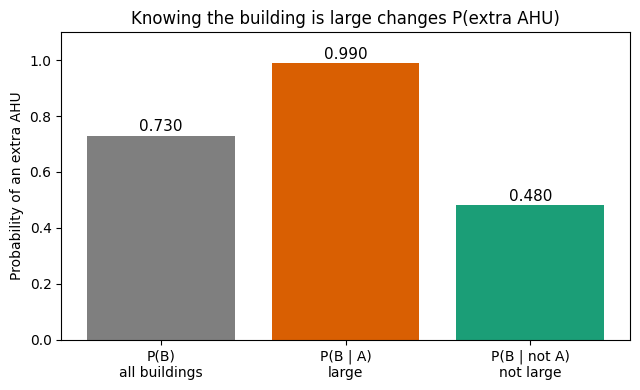

In [26]:
# --- 5.5 Conditional probability -------------------------------------------
import matplotlib.pyplot as plt
from math import isclose

def Pc(a, b):
    '''P(a | b) for two Boolean Series: count(a and b) / count(b).'''
    return (a & b).sum() / b.sum()

A, Bx = df.A_large, df.B_extra_ahu          # shared event columns from Section 4
n = len(df)

# 2 x 2 table of counts: the whole sample space split by A and B
counts_AB = pd.crosstab(
    A.map({True: 'A: large (n_zones > 64)', False: 'not A: not large'}),
    Bx.map({True: 'B: extra AHU', False: 'not B: no extra AHU'}),
    margins=True, margins_name='Total')
display(counts_AB)

# Route 1: definition  P(B|A) = P(A and B) / P(A)
P_A, P_B, P_AB = A.mean(), Bx.mean(), (A & Bx).mean()
P_B_given_A = P_AB / P_A
P_B_given_notA = (~A & Bx).mean() / (~A).mean()

# Route 2: restrict the rows first, then take the share (reduced sample space)
assert isclose(P_B_given_A, Bx[A].mean())
assert isclose(P_B_given_notA, Bx[~A].mean())
assert isclose(P_B_given_A, Pc(Bx, A)) and isclose(P_B_given_notA, Pc(Bx, ~A))

print(f"P(A)         = {A.sum()}/{n} = {P_A:.4f}")
print(f"P(B)         = {Bx.sum()}/{n} = {P_B:.4f}")
print(f"P(A and B)   = {(A & Bx).sum()}/{n} = {P_AB:.4f}")
print(f"P(B | A)     = {(A & Bx).sum()}/{A.sum()} = {P_B_given_A:.4f}   (extra AHU, among LARGE buildings)")
print(f"P(B | not A) = {(~A & Bx).sum()}/{(~A).sum()} = {P_B_given_notA:.4f}   (extra AHU, among NOT-large buildings)")
print(f"Difference   = {P_B_given_A - P_B_given_notA:.4f};  P(B|A) / P(B) = {P_B_given_A / P_B:.3f}")

# Sanity check against the numbers quoted in the interpretation below
assert (round(P_B_given_A, 4), round(P_B_given_notA, 4), round(P_B, 4)) == (0.9898, 0.4804, 0.73)

# Does the picture depend on the 64-zone threshold? (local masks: df is not modified)
rows = []
for t in (40, 50, 64, 80, 100):
    big = df.n_zones > t
    rows.append({'large means n_zones >': t, 'N(large)': int(big.sum()),
                 'P(B | large)': Pc(Bx, big), 'P(B | not large)': Pc(Bx, ~big)})
threshold_check = pd.DataFrame(rows)
display(threshold_check.round(3))

# Why? Look at the generator's own AHU rule (all checked on the data, not assumed)
need_more = df.min_ahus_required > df.ahus_configured
assert (need_more == Bx).all()                                   # B  <=>  required AHUs > configured AHUs
assert (df.min_ahus_required == np.ceil(df.n_zones / 10)).all()  # required AHUs = ceil(n_zones / 10)
big70 = df.n_zones > 70
print("\nrequired AHUs = ceil(n_zones/10) in every row; configured AHUs range", df['ahu.num_ahus'].min(), "to", df['ahu.num_ahus'].max())
print(f"P(B | n_zones > 70) = {Pc(Bx, big70):.3f}  ({int(big70.sum())} buildings)")
print("Large buildings WITHOUT extra AHU:")
display(df.loc[A & ~Bx, ['seed', 'n_zones', 'ahu.num_ahus', 'min_ahus_required', 'floor_plan.num_floors']])

# Chart: unconditional vs conditional extra-AHU probability
fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ['P(B)\nall buildings', 'P(B | A)\nlarge', 'P(B | not A)\nnot large']
vals = [P_B, P_B_given_A, P_B_given_notA]
bars = ax.bar(labels, vals, color=['#7f7f7f', '#d95f02', '#1b9e77'])
for b_, v in zip(bars, vals):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.015, f'{v:.3f}', ha='center', fontsize=11)
ax.set_ylim(0, 1.1); ax.set_ylabel('Probability of an extra AHU')
ax.set_title('Knowing the building is large changes P(extra AHU)')
plt.tight_layout(); plt.show()

**Interpretation (5.5).** Among the 98 large buildings, 97 needed extra AHUs: `P(B | A) = 97/98 = 0.990`. Among the 102 not-large buildings only 49 did: `P(B | not A) = 49/102 = 0.480`. The unconditional `P(B) = 0.730` sits in between because it averages the two groups. Learning that a building is large raises the chance of an extra AHU by about 51 percentage points, so size is a very strong predictor of `B`.

The data shows why: the generator requires `ceil(n_zones / 10)` AHUs and only configures 3 to 7 of them, so a building has an extra AHU exactly when the required number exceeds the configured number. Any building with more than 70 zones needs at least 8 AHUs and therefore *always* has extra ones (`P = 1.000`); the single large building without an extra AHU has 65 zones and 7 configured AHUs. The gap between large and not-large remains big for every threshold in the table, so it is not an artefact of choosing the median. This is a mechanical rule of the generator, i.e. an association in generated data, not a causal finding about real buildings.

### 5.6 Multiplication rule and chain rule (Member 3)

**Question.** What share of *all* buildings are both large and need extra AHUs, and can we build that joint probability from a marginal and a conditional probability? Can the same idea handle three events (4 floors, large, extra AHU)?

**Events and assumptions.** `A` and `B` as in 5.5; `F4` = the building has 4 floors (shared column `F4`). Same finite-population, equally-likely-rows assumption.

**Rule and why it fits.** The multiplication rule rearranges the definition of conditional probability:

$$P(A \cap B) = P(A)\,P(B \mid A) = P(B)\,P(A \mid B).$$

It is the right tool because we already know a conditional probability (`P(B | A)`) and want the joint probability. The plain product `P(A) P(B)` would be correct only if `A` and `B` were independent, which the next calculation shows is *not* the case. For three events the chain rule extends it:

$$P(F_4 \cap A \cap B) = P(F_4)\,P(A \mid F_4)\,P(B \mid F_4 \cap A).$$

In [27]:
# --- 5.6 Multiplication rule and chain rule --------------------------------
F4 = df.F4

# Two events: P(A and B) three ways
joint_rule_1 = P_A * Pc(Bx, A)                 # P(A) * P(B|A)
joint_rule_2 = P_B * Pc(A, Bx)                 # P(B) * P(A|B)   (other order, same answer)
joint_direct = (A & Bx).mean()                 # direct count: 97 / 200
joint_if_independent = P_A * P_B               # what the plain product would give

print(f"P(A) P(B|A)             = {P_A:.4f} x {Pc(Bx, A):.4f} = {joint_rule_1:.4f}")
print(f"P(B) P(A|B)             = {P_B:.4f} x {Pc(A, Bx):.4f} = {joint_rule_2:.4f}")
print(f"direct count (A & B)    = {(A & Bx).sum()}/{n} = {joint_direct:.4f}")
print(f"P(A) P(B) if independent = {joint_if_independent:.4f}   <- does NOT match, so A and B are dependent")
assert isclose(joint_rule_1, joint_direct) and isclose(joint_rule_2, joint_direct)

# Three events: chain rule, each factor read from the data
p1 = F4.mean()                  # P(F4)
p2 = Pc(A, F4)                  # P(A | F4)
p3 = Pc(Bx, F4 & A)             # P(B | F4 and A)
chain = p1 * p2 * p3
chain_direct = (F4 & A & Bx).mean()
print(f"\nP(F4)         = {F4.sum()}/{n} = {p1:.4f}")
print(f"P(A | F4)     = {(F4 & A).sum()}/{F4.sum()} = {p2:.4f}")
print(f"P(B | F4 & A) = {(F4 & A & Bx).sum()}/{(F4 & A).sum()} = {p3:.4f}")
print(f"Chain rule    = {p1:.4f} x {p2:.4f} x {p3:.4f} = {chain:.4f}")
print(f"Direct count  = {(F4 & A & Bx).sum()}/{n} = {chain_direct:.4f}")
assert isclose(chain, chain_direct)

multiplication_table = pd.DataFrame({
    'quantity': ['P(A and B)', 'P(F4 and A and B)'],
    'rule-based': [joint_rule_1, chain],
    'direct count': [joint_direct, chain_direct],
    'count / 200': [f"{(A & Bx).sum()}/{n}", f"{(F4 & A & Bx).sum()}/{n}"]})
display(multiplication_table.round(4))

P(A) P(B|A)             = 0.4900 x 0.9898 = 0.4850
P(B) P(A|B)             = 0.7300 x 0.6644 = 0.4850
direct count (A & B)    = 97/200 = 0.4850
P(A) P(B) if independent = 0.3577   <- does NOT match, so A and B are dependent

P(F4)         = 63/200 = 0.3150
P(A | F4)     = 50/63 = 0.7937
P(B | F4 & A) = 50/50 = 1.0000
Chain rule    = 0.3150 x 0.7937 x 1.0000 = 0.2500
Direct count  = 50/200 = 0.2500


,quantity,rule-based,direct count,count / 200
0,P(A and B),0.485,0.485,97/200
1,P(F4 and A and B),0.250,0.250,50/200


**Interpretation (5.6).** About 48.5% of all accepted buildings are both large and need extra AHUs (`0.49 x 0.990 = 0.485 = 97/200`). If size and the extra-AHU need were independent we would expect only `0.49 x 0.73 = 0.358`, so the multiplication rule with the *conditional* factor is the correct way to get the joint probability here; the gap between 0.358 and 0.485 is itself evidence of dependence (formally assessed in Section 5.9 by Member 4). The chain rule shows the structure of the biggest group: 31.5% of buildings have 4 floors, 79.4% of those are large, and *every* 4-floor large building needs extra AHUs (`P(B | F4 and A) = 1`), giving 25% of all buildings. The rule-based and direct values agree exactly because both use the same 200-row population.

### 5.7 Total probability (Member 3)

**Question.** Can we recover the overall chance of an extra AHU, `P(B)`, from the floor-level extra-AHU rates and the floor mix alone, without ever counting `B` over all 200 rows?

**Events and assumptions.** The partition is `F2, F3, F4` (2, 3 or 4 floors). For the law to apply the events must be **mutually exclusive** and **exhaustive**, and `P(F_k) > 0`. This is checked in code (every building has exactly one floor count; 74 + 63 + 63 = 200). A second partition, `A` / `not A`, is used as a cross-check.

**Rule and why it fits.** The law of total probability:

$$P(B) = \sum_{k=2}^{4} P(B \mid F_k)\,P(F_k).$$

It fits because the extra-AHU rate clearly differs by floor count (we expect it to rise with floors), so `P(B)` is a weighted average of the group rates with the share of each group as weight. It is also the denominator needed for Bayes' theorem in Section 5.8.

In [28]:
# --- 5.7 Total probability ---------------------------------------------------
# 1) Check that F2, F3, F4 form a partition
floor_events = {k: df[f'F{k}'] for k in (2, 3, 4)}
assert ((df.F2.astype(int) + df.F3.astype(int) + df.F4.astype(int)) == 1).all()   # exactly one per row
assert sum(int(f.sum()) for f in floor_events.values()) == n                       # 74 + 63 + 63 = 200

# 2) Ingredients: P(F_k) and P(B | F_k)
pF   = {k: df[f'F{k}'].mean() for k in (2, 3, 4)}
pB_F = {k: Pc(Bx, df[f'F{k}']) for k in (2, 3, 4)}

# 3) Total probability
pB_total = sum(pB_F[k] * pF[k] for k in (2, 3, 4))

total_prob_table = pd.DataFrame({
    'floors': [2, 3, 4],
    'N(F_k)': [int(floor_events[k].sum()) for k in (2, 3, 4)],
    'P(F_k)': [pF[k] for k in (2, 3, 4)],
    'N(B and F_k)': [int((floor_events[k] & Bx).sum()) for k in (2, 3, 4)],
    'P(B | F_k)': [pB_F[k] for k in (2, 3, 4)],
    'P(B | F_k) x P(F_k)': [pB_F[k] * pF[k] for k in (2, 3, 4)]})
display(total_prob_table.round(4))
print(f"Total probability  P(B) = {' + '.join(f'{pB_F[k] * pF[k]:.3f}' for k in (2, 3, 4))} = {pB_total:.4f}")
print(f"Direct count       P(B) = {Bx.sum()}/{n} = {Bx.mean():.4f}")
assert isclose(pB_total, Bx.mean())

# 4) Cross-check with a different partition: A and not A
pB_total_A = P_A * Pc(Bx, A) + (1 - P_A) * Pc(Bx, ~A)
print(f"Partition A / not A: {P_A:.3f} x {Pc(Bx, A):.4f} + {1 - P_A:.3f} x {Pc(Bx, ~A):.4f} = {pB_total_A:.4f}")
assert isclose(pB_total_A, Bx.mean())

# 5) Joint probability table floors x extra AHU (the pieces of the law; reusable for a heatmap)
joint_F_B = pd.crosstab(df['floor_plan.num_floors'], Bx, normalize='all')
joint_F_B.columns = ['no extra AHU (not B)', 'extra AHU (B)']
joint_F_B.index.name = 'floors'
display(joint_F_B.round(4))
assert isclose(joint_F_B['extra AHU (B)'].sum(), pB_total)    # column sum = P(B)

,floors,N(F_k),P(F_k),N(B and F_k),P(B | F_k),P(B | F_k) x P(F_k)
0,2,74,0.370,39,0.5270,0.195
1,3,63,0.315,49,0.7778,0.245
2,4,63,0.315,58,0.9206,0.290


Total probability  P(B) = 0.195 + 0.245 + 0.290 = 0.7300
Direct count       P(B) = 146/200 = 0.7300
Partition A / not A: 0.490 x 0.9898 + 0.510 x 0.4804 = 0.7300


,no extra AHU (not B),extra AHU (B)
floors,,
2,0.175,0.195
3,0.070,0.245
4,0.025,0.290


**Interpretation (5.7).** The extra-AHU rate climbs with the number of floors: `P(B | F2) = 39/74 = 0.527`, `P(B | F3) = 49/63 = 0.778`, `P(B | F4) = 58/63 = 0.921`. Weighting these rates by the floor mix (0.370, 0.315, 0.315) gives `0.195 + 0.245 + 0.290 = 0.730`, exactly the direct count `146/200`. The agreement is exact (not approximate) because the same 200 buildings feed both routes and the partition is valid; a mismatch would signal an overlapping or incomplete partition. The `A` / `not A` partition gives the same 0.730, showing that the result does not depend on which partition is used. More floors means more zones in this generator, which is why taller buildings more often need extra AHUs; the overall 73% is a blend of a roughly 50/50 situation for 2-floor buildings and a near-certain one for 4-floor buildings.

### 5.8 Bayes' theorem (Member 3)

**Question.** Suppose we are told only that a building needed extra AHUs. How likely is it to have 4 floors (and how likely is it to be large)? Conversely, how does the answer change if we are told it needed *no* extra AHU?

**Events and assumptions.** Prior: `P(F_k)` (floor mix before any evidence). Evidence: `B` (extra AHU observed). Posterior: `P(F_k | B)`. We know the forward rates `P(B | F_k)` from 5.7 and want to reverse the direction of the conditioning. Finite population of 200 accepted buildings, as before.

**Rule and why it fits.** Bayes' theorem:

$$P(F_k \mid B) = \frac{P(B \mid F_k)\,P(F_k)}{P(B)}, \qquad P(B) = \sum_j P(B \mid F_j)\,P(F_j).$$

It fits because the data naturally give "given the floors, how often is there an extra AHU?" but the question asks the reverse, "given an extra AHU, what are the floors?". The denominator is the total-probability result from 5.7, so 5.7 and 5.8 work as a pair. The same formula answers `P(A | B) = P(B | A) P(A) / P(B)`.

,floors,prior P(F_k),likelihood P(B | F_k),posterior P(F_k | B),direct count among B,posterior P(F_k | not B)
0,2,0.370,0.5270,0.2671,39/146,0.6481
1,3,0.315,0.7778,0.3356,49/146,0.2593
2,4,0.315,0.9206,0.3973,58/146,0.0926


P(F4 | B) = (0.9206 x 0.315) / 0.730 = 0.3973   direct: 58/146 = 0.3973
P(A | B) = (0.9898 x 0.49) / 0.73 = 0.6644   direct: 97/146 = 0.6644   prior P(A) = 0.49

P(B | A) = 0.990  vs  P(A | B) = 0.664   (not the same question!)


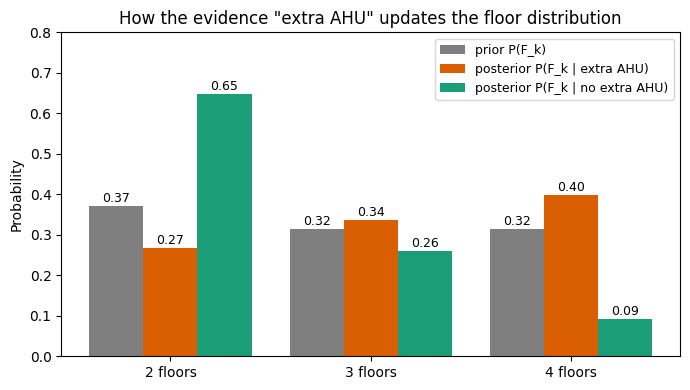

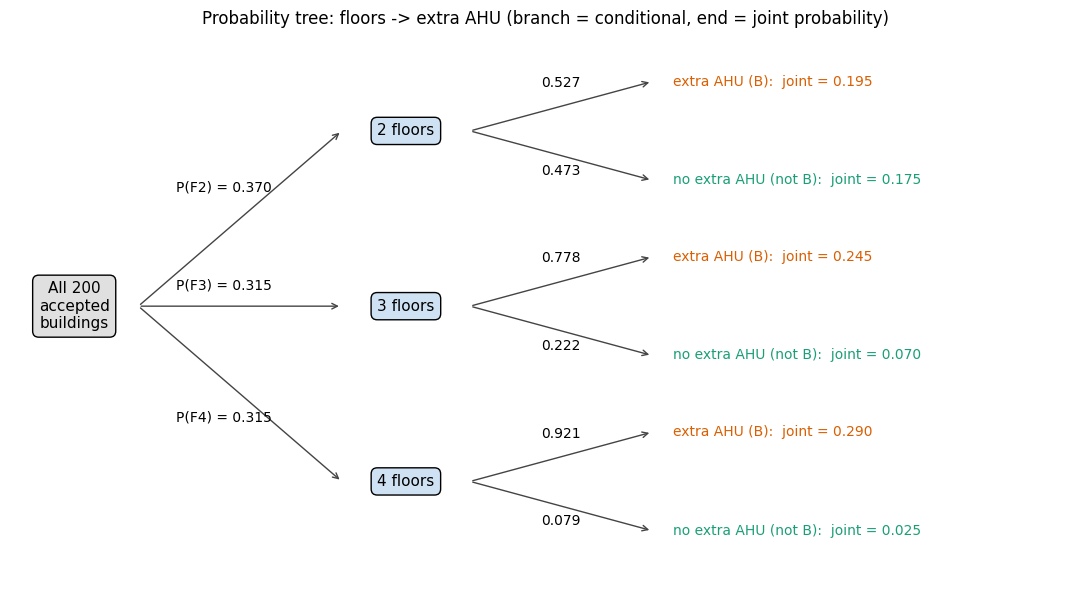

In [29]:
# --- 5.8 Bayes' theorem ------------------------------------------------------
# Posterior P(F_k | B) for every floor count (evidence: an extra AHU was needed)
post = {k: pB_F[k] * pF[k] / pB_total for k in (2, 3, 4)}
post_F4 = post[4]
direct_post = {k: Pc(df[f'F{k}'], Bx) for k in (2, 3, 4)}        # direct count among B rows
for k in (2, 3, 4):
    assert isclose(post[k], direct_post[k])
assert isclose(sum(post.values()), 1.0)                          # posteriors form a distribution

# Evidence in the other direction: no extra AHU (not B)
pnotB = 1 - pB_total
post_notB = {k: (1 - pB_F[k]) * pF[k] / pnotB for k in (2, 3, 4)}
for k in (2, 3, 4):
    assert isclose(post_notB[k], Pc(df[f'F{k}'], ~Bx))

prior_posterior = pd.DataFrame({
    'floors': [2, 3, 4],
    'prior P(F_k)': [pF[k] for k in (2, 3, 4)],
    'likelihood P(B | F_k)': [pB_F[k] for k in (2, 3, 4)],
    'posterior P(F_k | B)': [post[k] for k in (2, 3, 4)],
    'direct count among B': [f"{int((df[f'F{k}'] & Bx).sum())}/{int(Bx.sum())}" for k in (2, 3, 4)],
    'posterior P(F_k | not B)': [post_notB[k] for k in (2, 3, 4)]})
display(prior_posterior.round(4))
print(f"P(F4 | B) = ({pB_F[4]:.4f} x {pF[4]:.3f}) / {pB_total:.3f} = {post_F4:.4f}   direct: 58/146 = {58 / 146:.4f}")

# Second Bayes question: P(A | B), "of the buildings with extra AHUs, how many are large?"
post_A_given_B = Pc(Bx, A) * P_A / P_B
print(f"P(A | B) = ({Pc(Bx, A):.4f} x {P_A:.2f}) / {P_B:.2f} = {post_A_given_B:.4f}   direct: 97/146 = {97 / 146:.4f}   prior P(A) = {P_A:.2f}")
assert isclose(post_A_given_B, Pc(A, Bx)) and isclose(post_F4, 58 / 146)

# Direction check: the two conditional probabilities are very different
print(f"\nP(B | A) = {Pc(Bx, A):.3f}  vs  P(A | B) = {Pc(A, Bx):.3f}   (not the same question!)")

# Chart 1: prior vs posterior
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3); w = 0.27
ax.bar(x - w, [pF[k] for k in (2, 3, 4)], w, label='prior P(F_k)', color='#7f7f7f')
ax.bar(x, [post[k] for k in (2, 3, 4)], w, label='posterior P(F_k | extra AHU)', color='#d95f02')
ax.bar(x + w, [post_notB[k] for k in (2, 3, 4)], w, label='posterior P(F_k | no extra AHU)', color='#1b9e77')
for xs, vals in ((x - w, [pF[k] for k in (2, 3, 4)]), (x, [post[k] for k in (2, 3, 4)]), (x + w, [post_notB[k] for k in (2, 3, 4)])):
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['2 floors', '3 floors', '4 floors'])
ax.set_ylabel('Probability'); ax.set_ylim(0, 0.8)
ax.set_title('How the evidence "extra AHU" updates the floor distribution')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

# Chart 2: probability tree floors -> extra AHU (branch probabilities and joint probabilities)
fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
arrow = dict(arrowstyle='->', color='#444444')
ax.text(0.06, 0.5, 'All 200\naccepted\nbuildings', ha='center', va='center', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', fc='#e0e0e0'))
floor_y = {2: 0.82, 3: 0.50, 4: 0.18}
for k in (2, 3, 4):
    fy = floor_y[k]
    ax.annotate('', xy=(0.31, fy), xytext=(0.12, 0.5), arrowprops=arrow)
    ax.text(0.20, (0.5 + fy) / 2 + (0.05 if k == 2 else -0.05 if k == 4 else 0.03),
            f'P(F{k}) = {pF[k]:.3f}', ha='center', fontsize=10)
    ax.text(0.37, fy, f'{k} floors', ha='center', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.4', fc='#cfe2f3'))
    for is_b, dy, lab, col in ((True, 0.09, 'extra AHU (B)', '#d95f02'), (False, -0.09, 'no extra AHU (not B)', '#1b9e77')):
        ly = fy + dy
        p_cond = pB_F[k] if is_b else 1 - pB_F[k]
        ax.annotate('', xy=(0.60, ly), xytext=(0.43, fy), arrowprops=arrow)
        ax.text(0.515, (fy + ly) / 2 + (0.035 if is_b else -0.035), f'{p_cond:.3f}', ha='center', fontsize=10)
        ax.text(0.62, ly, f'{lab}:  joint = {pF[k] * p_cond:.3f}', va='center', fontsize=10, color=col)
ax.set_title('Probability tree: floors -> extra AHU (branch = conditional, end = joint probability)', fontsize=12)
plt.tight_layout(); plt.show()

**Interpretation (5.8).** *Prior* = what we believed about the floor count before seeing any evidence (31.5% four-floor); *posterior* = the updated belief after learning the building needed extra AHUs. Seeing that evidence raises the probability of 4 floors from 0.315 to `(58/63 x 0.315) / 0.73 = 0.397` (`= 58/146`, matching the direct count) and lowers the probability of 2 floors from 0.370 to 0.267. Hearing "no extra AHU" pushes the other way: the 4-floor share falls to 0.093 (5 of 54 buildings) and 2-floor buildings become the majority (0.648). In the same way, among buildings with extra AHUs about two thirds are large (`P(A | B) = 97/146 = 0.664`, up from the prior 0.49).

Two cautions. First, `P(B | A) = 0.990` and `P(A | B) = 0.664` answer different questions; the first is high because almost all large buildings need extra AHUs, the second is lower because many *not-large* buildings (49 of 146) also need them. Second, the posterior is a re-weighting of the observed buildings, not a causal statement: the extra AHU is "evidence" about the floors only because the generator links floors, size and AHU requirements.

#### Hand-off to Member 4 (validation): rule-based results from Sections 5.5-5.8

All values below are pulled live from the cells above (nothing is typed in by hand). Member 4's validation cells can use the variables `Pc`, `A`, `Bx`, `pF`, `pB_F`, `pB_total`, `post_F4` and the dictionary `m3_results`.

In [30]:
# --- Hand-off dictionary: rule-based values (route 1 of the three-way validation) ---
m3_results = {
    'P(B|A)':          P_B_given_A,
    'P(B|not A)':      P_B_given_notA,
    'P(A and B)':      joint_rule_1,                 # multiplication rule
    'P(F4 and A and B)': chain,                      # chain rule
    'P(B)':            pB_total,                     # total probability
    'P(F4|B)':         post_F4,                      # Bayes
    'P(A|B)':          post_A_given_B,               # Bayes
    'P(F2|B)':         post[2],
    'P(F3|B)':         post[3],
}
display(pd.Series(m3_results, name='rule-based value').round(4).to_frame())

,rule-based value
P(B|A),0.9898
P(B|not A),0.4804
P(A and B),0.4850
P(F4 and A and B),0.2500
P(B),0.7300
P(F4|B),0.3973
P(A|B),0.6644
P(F2|B),0.2671
P(F3|B),0.3356


## 6. Validation (Member 4)

Add independent validation calculations, Monte Carlo comparison, bootstrap interval, and preprocessing sensitivity analysis here.

## 7. Insights and limitations (Member 5)

Summarize findings with numbers, discuss limitations, and explain relevance to the Smart Buildings competition.